# Atlas Insight — Nhóm 12
Notebook đọc kết quả đã tạo; không ghi đè data/model. Chạy `python run_pipeline.py` khi cần tái tạo.
Nguồn: https://api.worldbank.org/v2/country/all/indicator/SP.DYN.LE00.IN và https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT/'reports').exists(): ROOT = ROOT.parent
assert (ROOT/'reports').exists()
R=json.loads((ROOT/'reports/model_results.json').read_text())

## Crawl Scrapy World Bank

In [2]:
display(json.loads((ROOT/'reports/crawl_audit.json').read_text()))

{'source_url': 'https://api.worldbank.org/v2/country/all/indicator/SP.DYN.LE00.IN?format=json&date=1952:2007&per_page=20000',
 'tool': 'Scrapy',
 'downloaded_at_utc': '2026-10-31T13:46:26.950913+00:00',
 'records': 12768,
 'attributes': ['iso_alpha',
  'country_worldbank',
  'year',
  'life_expectancy',
  'indicator_id',
  'indicator_name',
  'unit',
  'obs_status'],
 'pages': [1],
 'sha256': '944f7010864530d29676f0ec5be0d218a44bd1b64dfcc30b1b2c091259841bc9',
 'mode': 'live_http',
 'http_200': 1}

## Tích hợp hai nguồn

In [3]:
display(pd.read_csv(ROOT/'reports/multisource_audit.csv'))

,data_source,records,countries,missing_life_exp
0,Gapminder,1704,142,0
1,World Bank,1400,140,6


## Missingness trước/sau

In [4]:
display(pd.read_csv(ROOT/'reports/missingness_before.csv'))

,column,missing_count,missing_percent
0,continent,0,0.000
1,country,0,0.000
2,data_feed,0,0.000
3,gdp_per_capita,0,0.000
4,iso_alpha,0,0.000
5,iso_num,0,0.000
6,life_expectancy,0,0.000
7,population,0,0.000
8,year,0,0.000
9,record_id,0,0.000


## Thống kê đơn biến

In [5]:
display(pd.read_csv(ROOT/'reports/univariate_statistics.csv'))

,Unnamed: 0,mean,median,std,skew,kurt
0,life_expectancy,5.947444e+01,6.071250e+01,1.291711e+01,-0.252702,-1.126685
1,gdp_per_capita,7.215327e+03,3.531847e+03,9.857455e+03,3.850272,27.515894
2,population,2.960121e+07,7.023596e+06,1.061579e+08,8.340218,77.948203
3,sim_health_index,7.188751e+01,7.167000e+01,1.389063e+01,-0.083126,-0.429492
4,sim_education_index,7.250249e+01,7.246500e+01,1.330374e+01,-0.028616,-0.440416
5,sim_trend_index,7.380964e+01,7.351500e+01,1.304957e+01,-0.087618,-0.283665


## Bảng liên ngẫu

In [6]:
display(pd.read_csv(ROOT/'reports/crosstab_continent_policy.csv'))

,continent,Higher simulated investment,Lower simulated investment,Moderate simulated investment,Unknown
0,Africa,0.293269,0.158654,0.500000,0.048077
1,Americas,0.536667,0.033333,0.366667,0.063333
2,Asia,0.462121,0.085859,0.404040,0.047980
3,Europe,0.708333,0.022222,0.227778,0.041667
4,Oceania,0.791667,0.000000,0.125000,0.083333


## 01 missingness

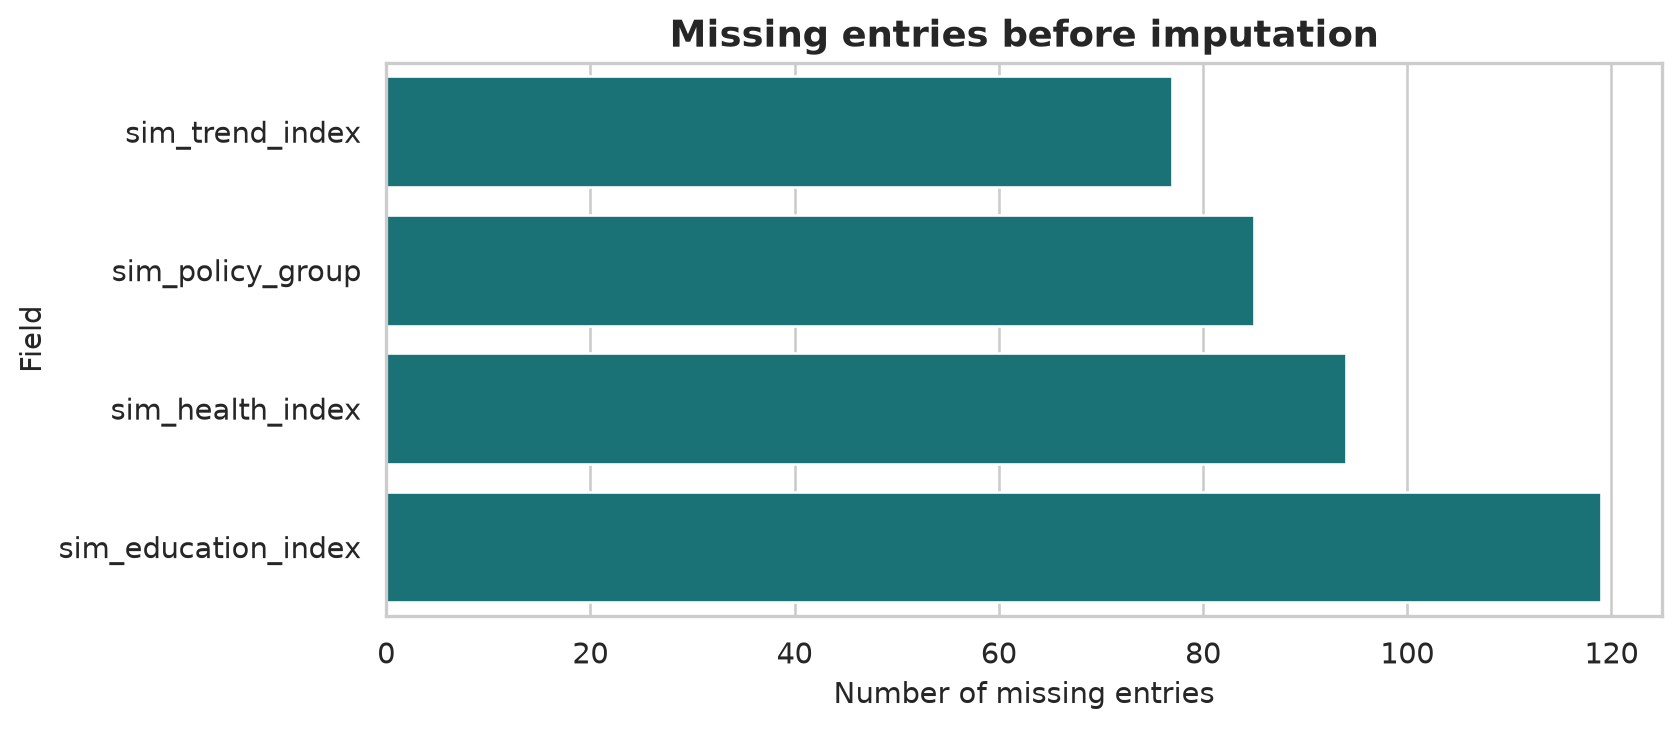

In [7]:
display(Image(filename=str(ROOT/'charts/01_missingness.png'), width=800))

**So what?** 375 ô thiếu ở sim_*. Dữ liệu quan trắc Gapminder không bị cố ý xóa.

## 02 imputation distribution

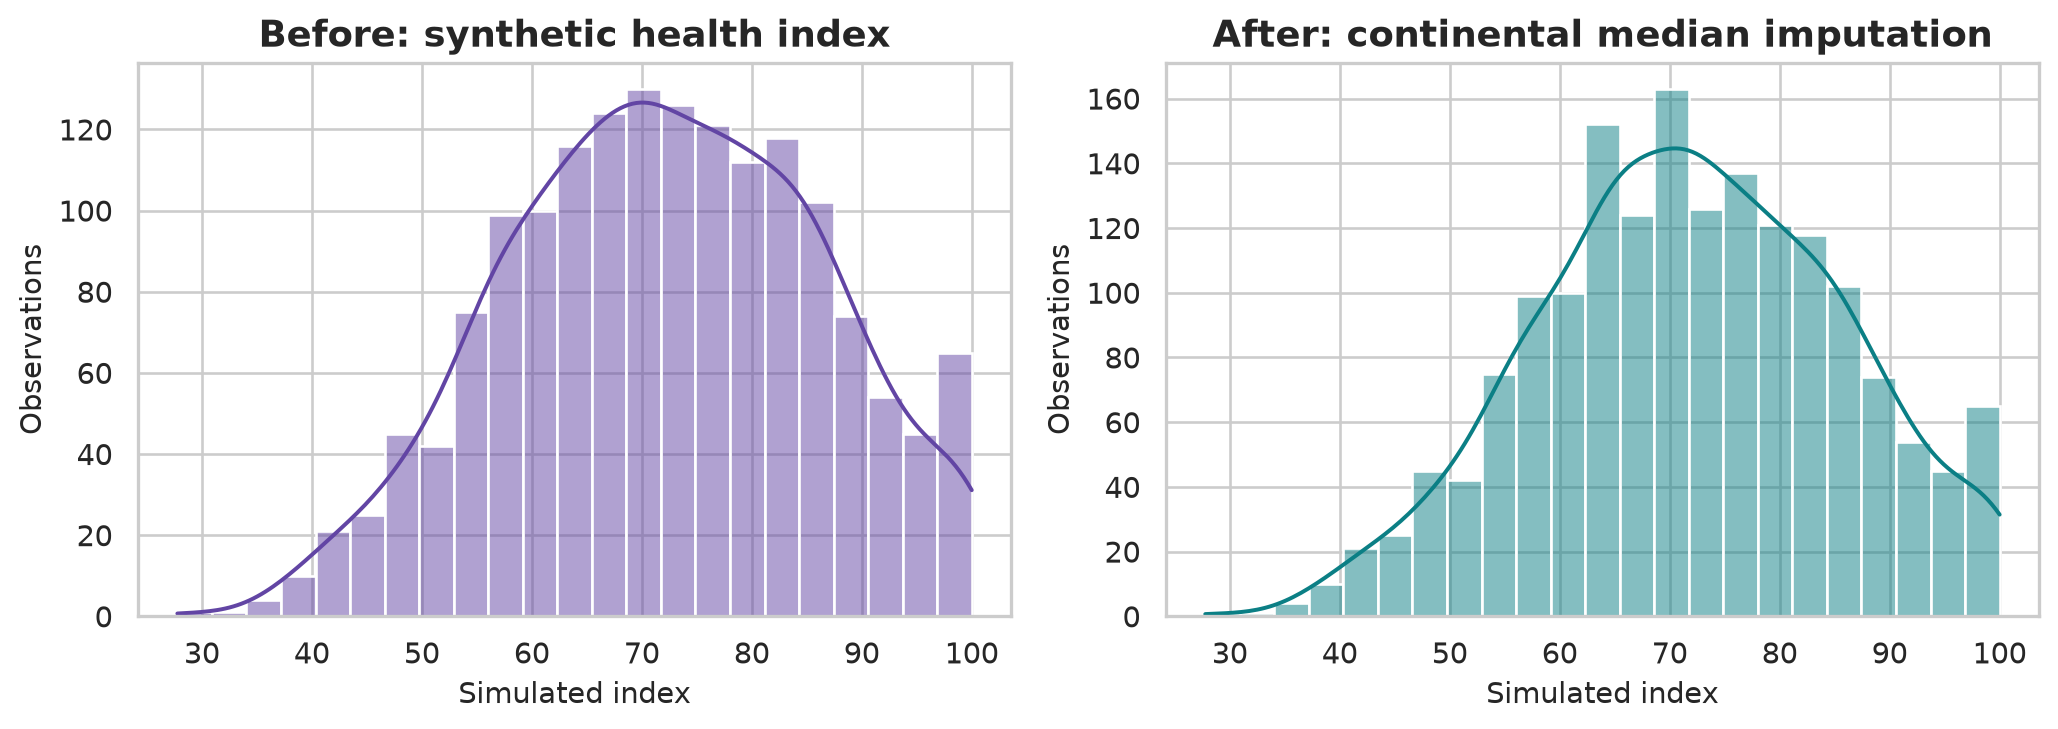

In [8]:
display(Image(filename=str(ROOT/'charts/02_imputation_distribution.png'), width=800))

**So what?** Median thay đổi hình dạng phân phối; so sánh thêm mean/median/std trong imputation_impact.csv.

## 03 life expectancy hist kde

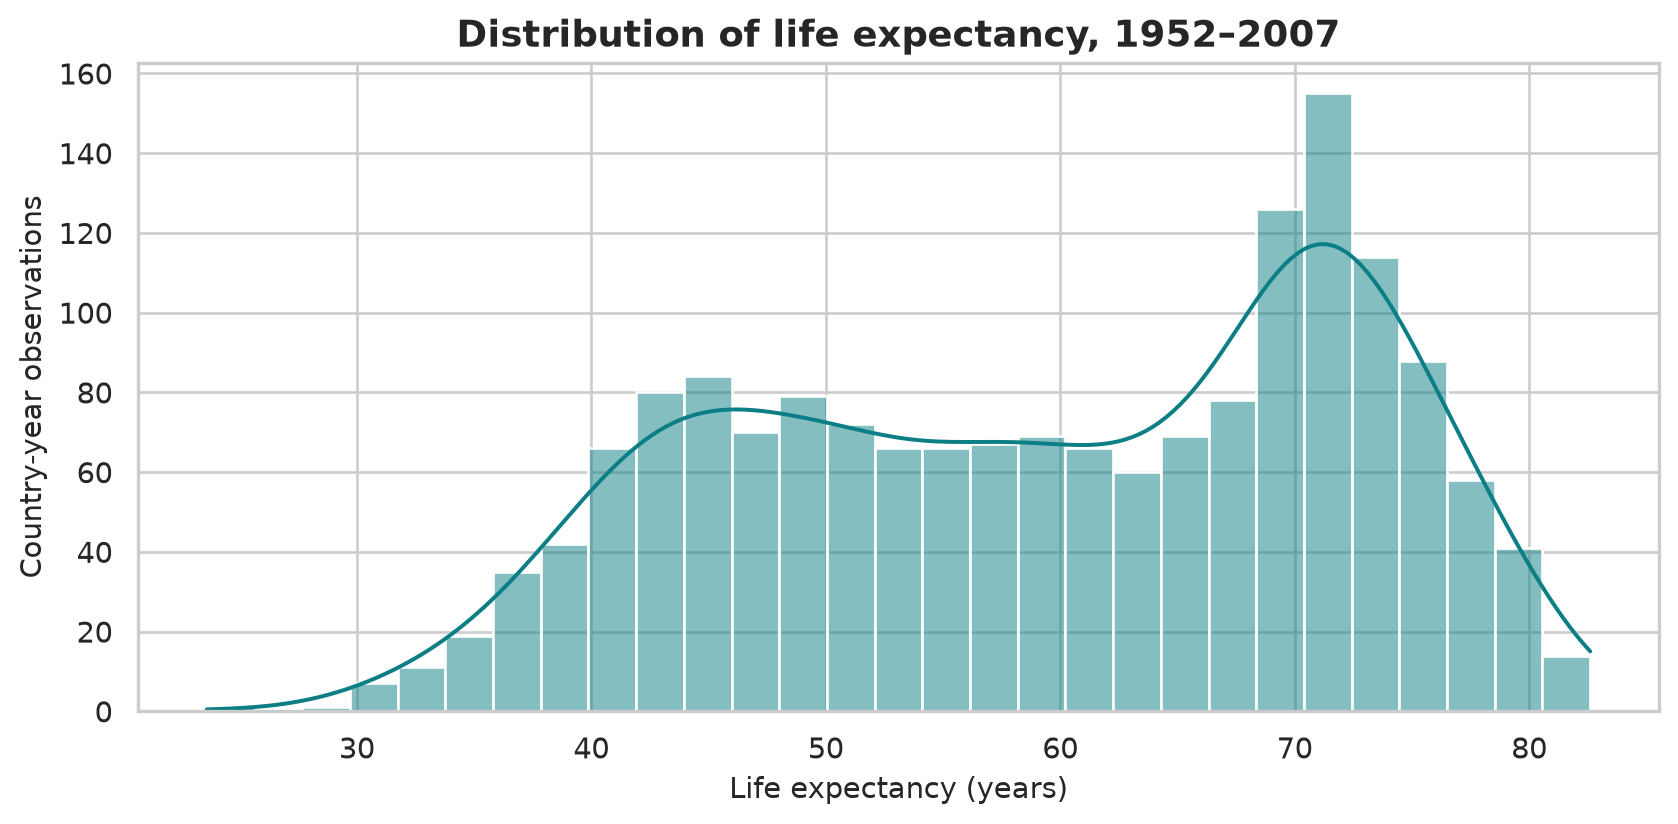

In [9]:
display(Image(filename=str(ROOT/'charts/03_life_expectancy_hist_kde.png'), width=800))

**So what?** Tuổi thọ phân tán theo nước/năm; giữ year và continent trong feature.

## 04 life expectancy box iqr

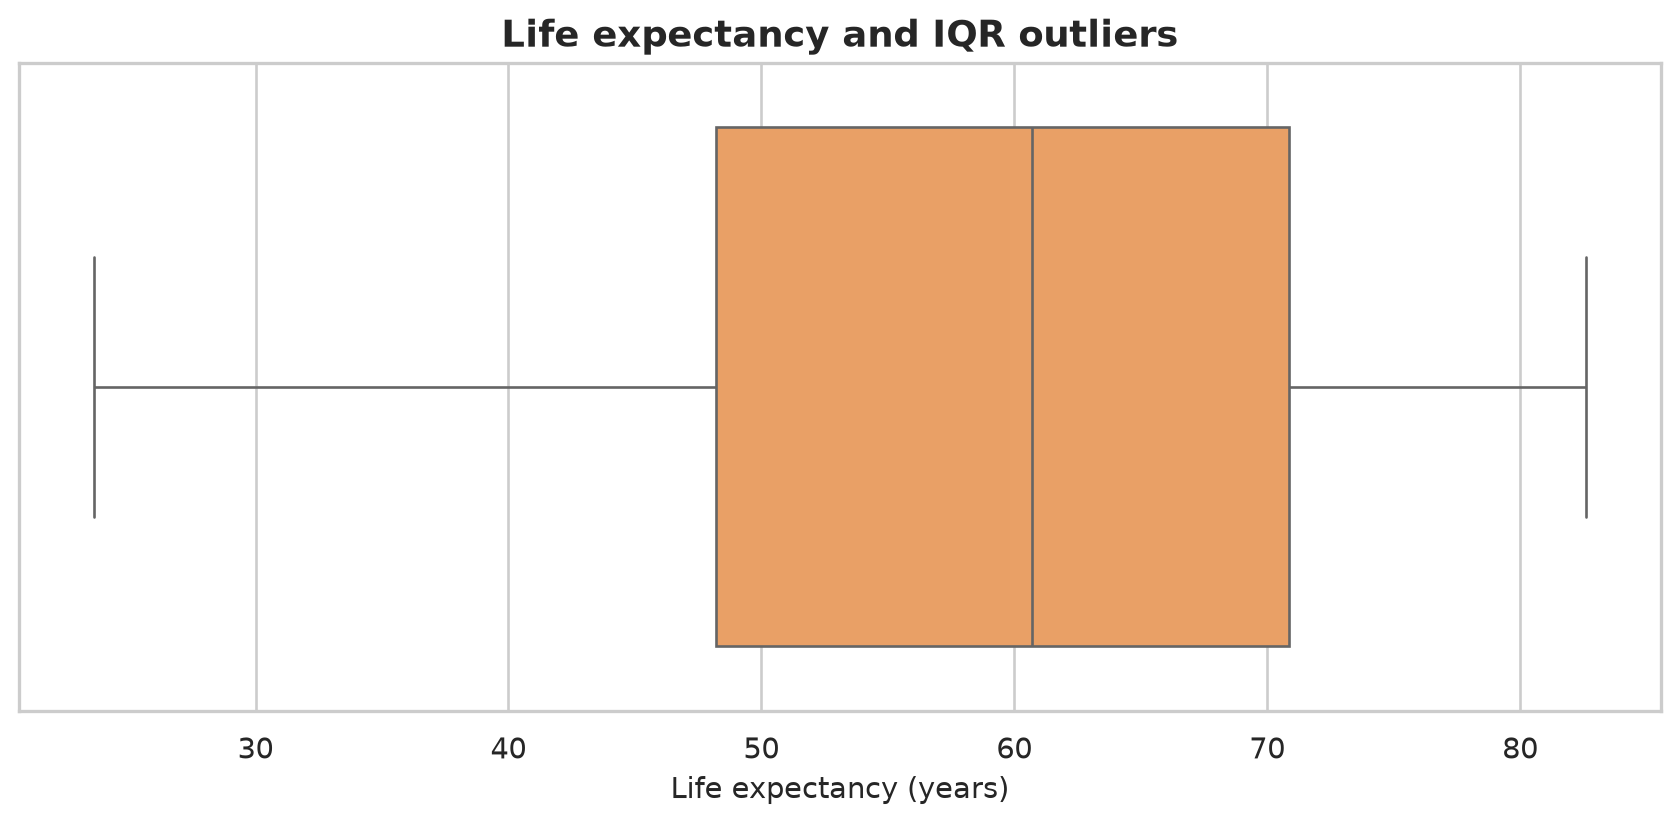

In [10]:
display(Image(filename=str(ROOT/'charts/04_life_expectancy_box_iqr.png'), width=800))

**So what?** IQR tuổi thọ không đánh dấu ngoại lai. GDP/dân số được log và IQR clipping trong pipeline ML; không cắt target.

## 05 continent bar

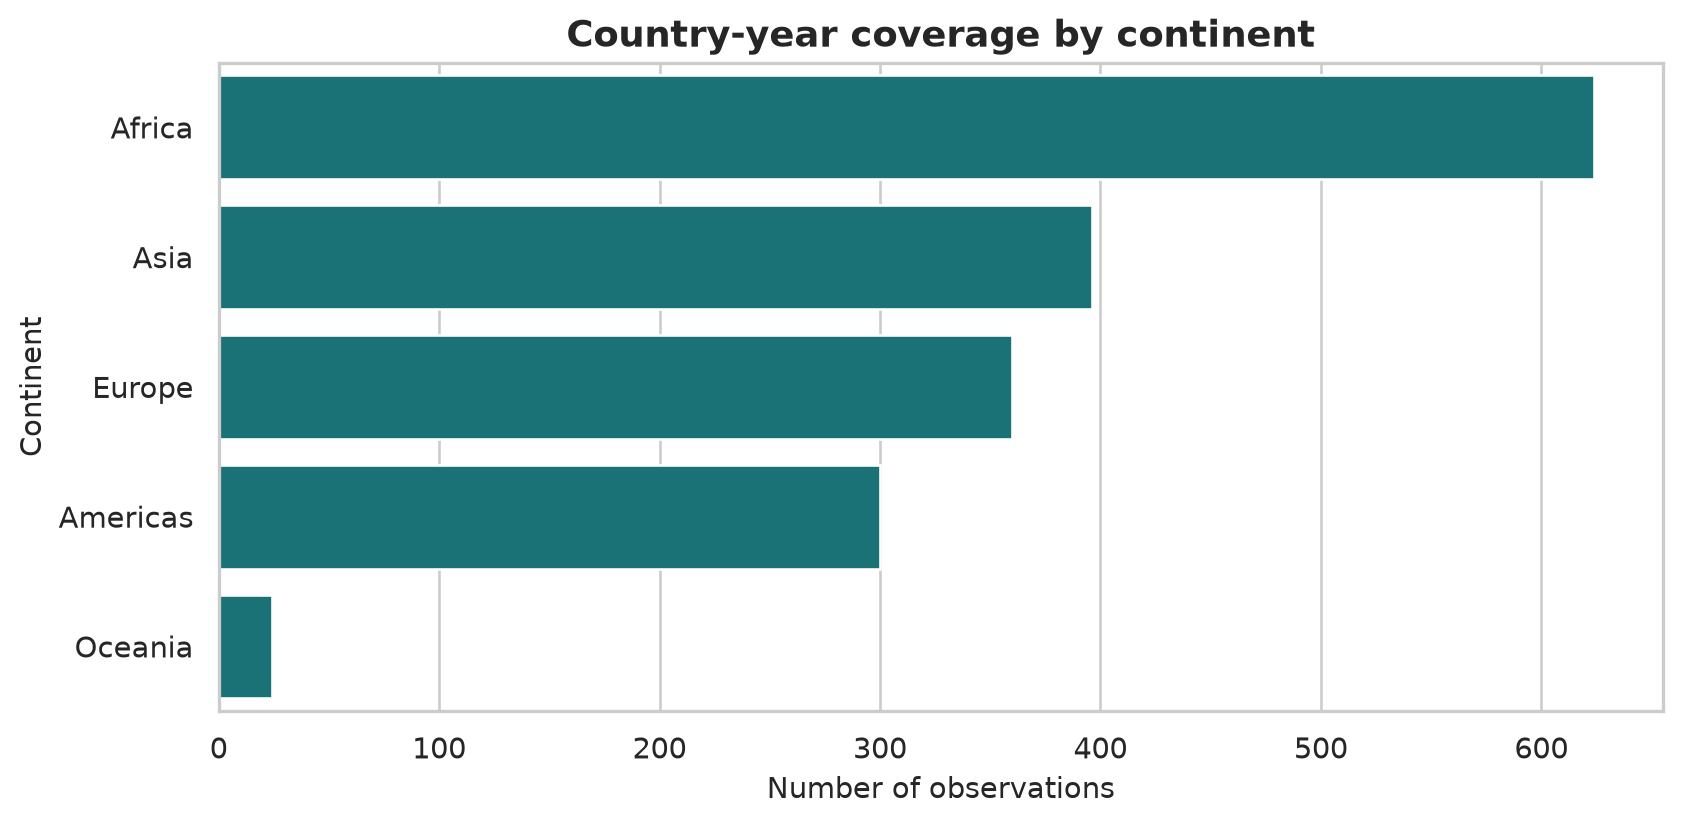

In [11]:
display(Image(filename=str(ROOT/'charts/05_continent_bar.png'), width=800))

**So what?** Phân bố châu lục lệch. Outer split phân tầng châu lục theo danh sách nước.

## 06 correlation heatmap

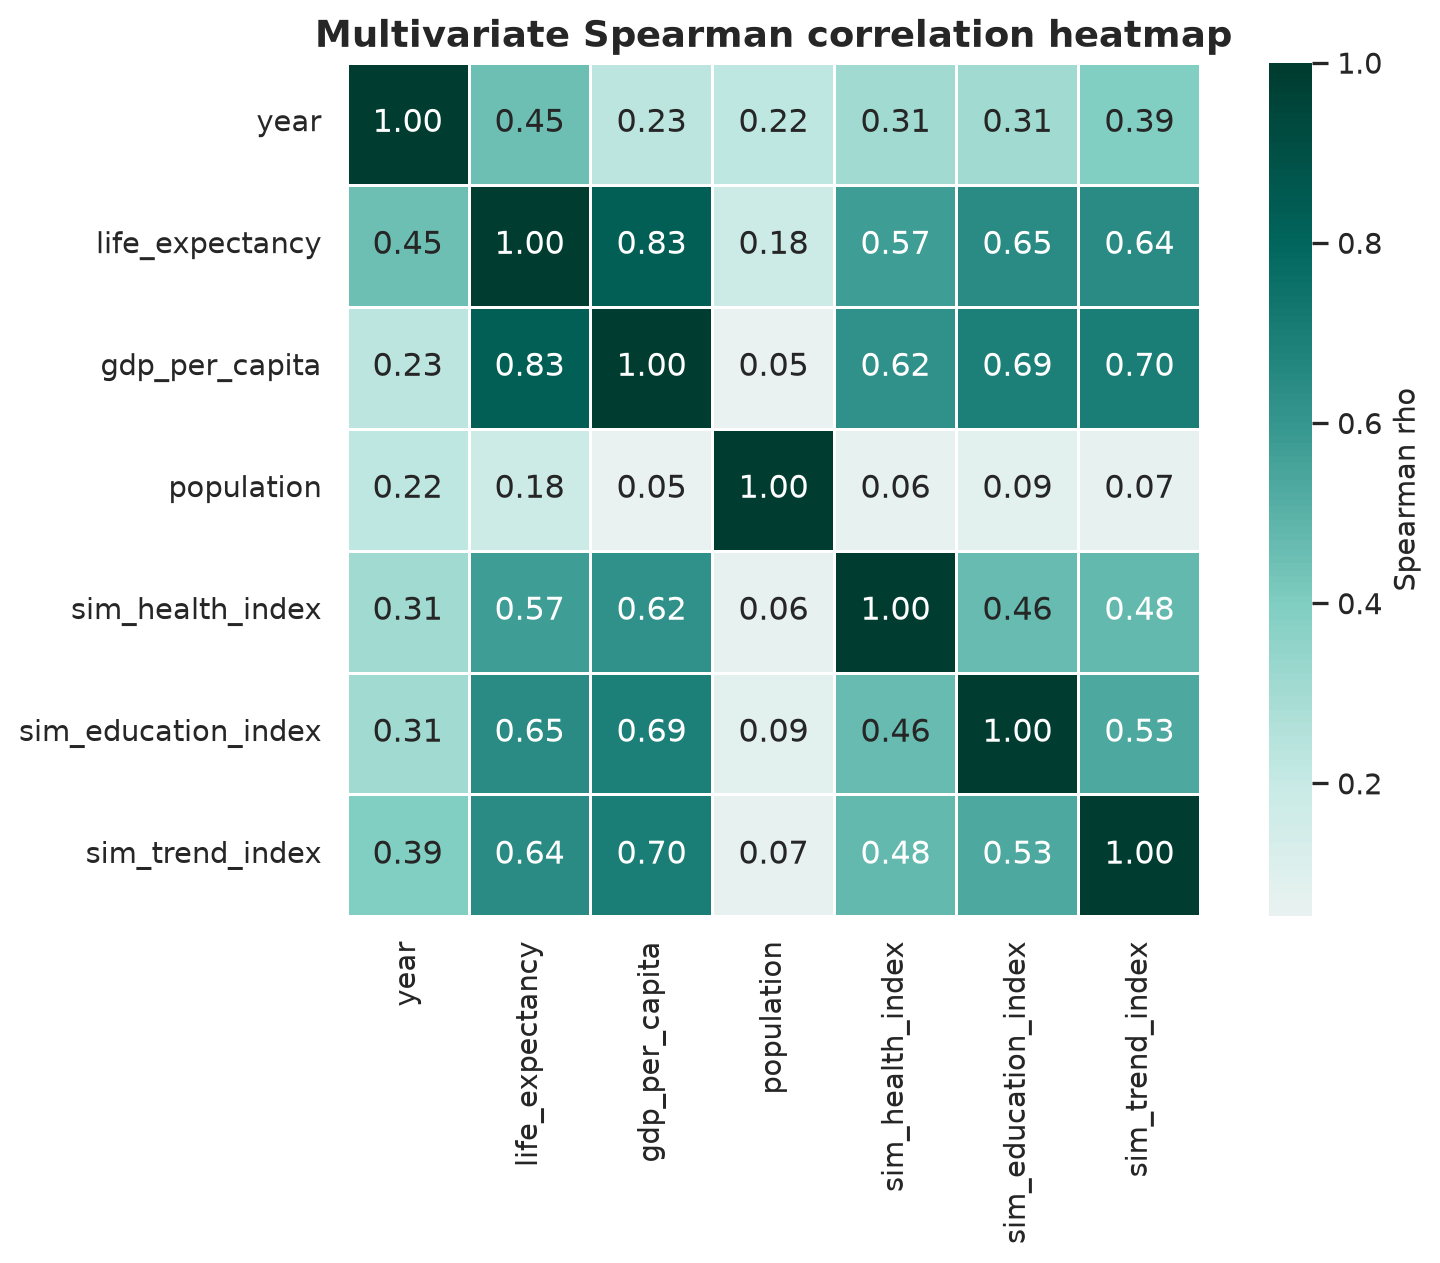

In [12]:
display(Image(filename=str(ROOT/'charts/06_correlation_heatmap.png'), width=800))

**So what?** Spearman GDP–tuổi thọ ≈0,8265; gợi ý feature dự báo, không phải nhân quả.

## 07 gdp lifeexp scatter

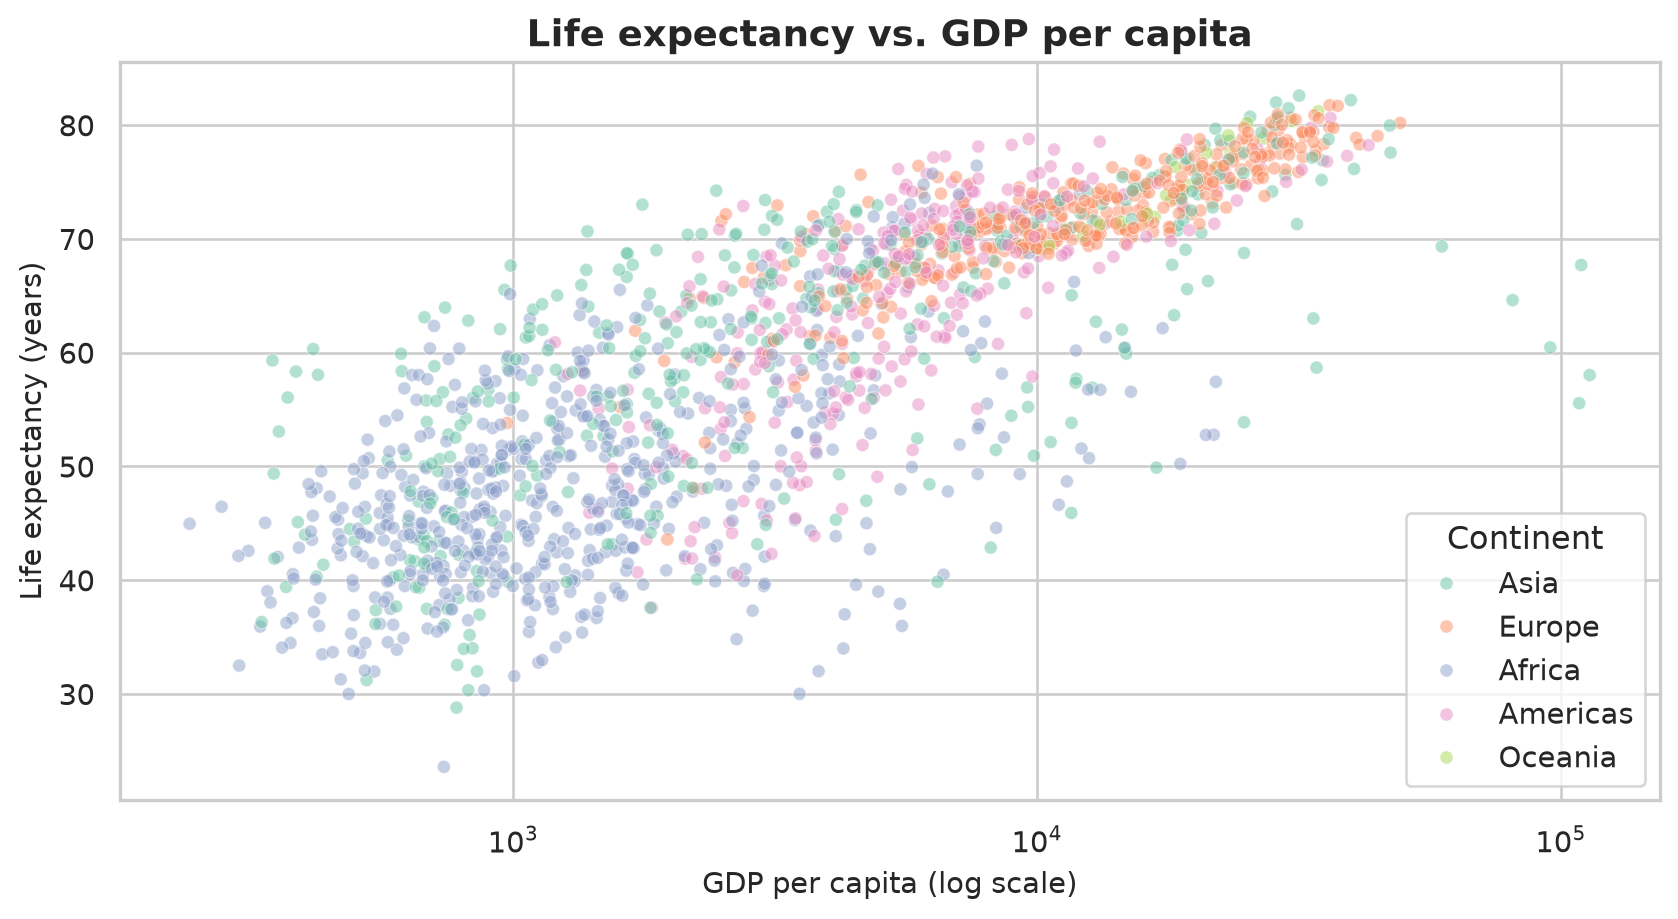

In [13]:
display(Image(filename=str(ROOT/'charts/07_gdp_lifeexp_scatter.png'), width=800))

**So what?** GDP có đuôi dài; log1p và đối chứng tuyến tính/cây kiểm tra tính phi tuyến.

## 08 continent lifeexp grouped box

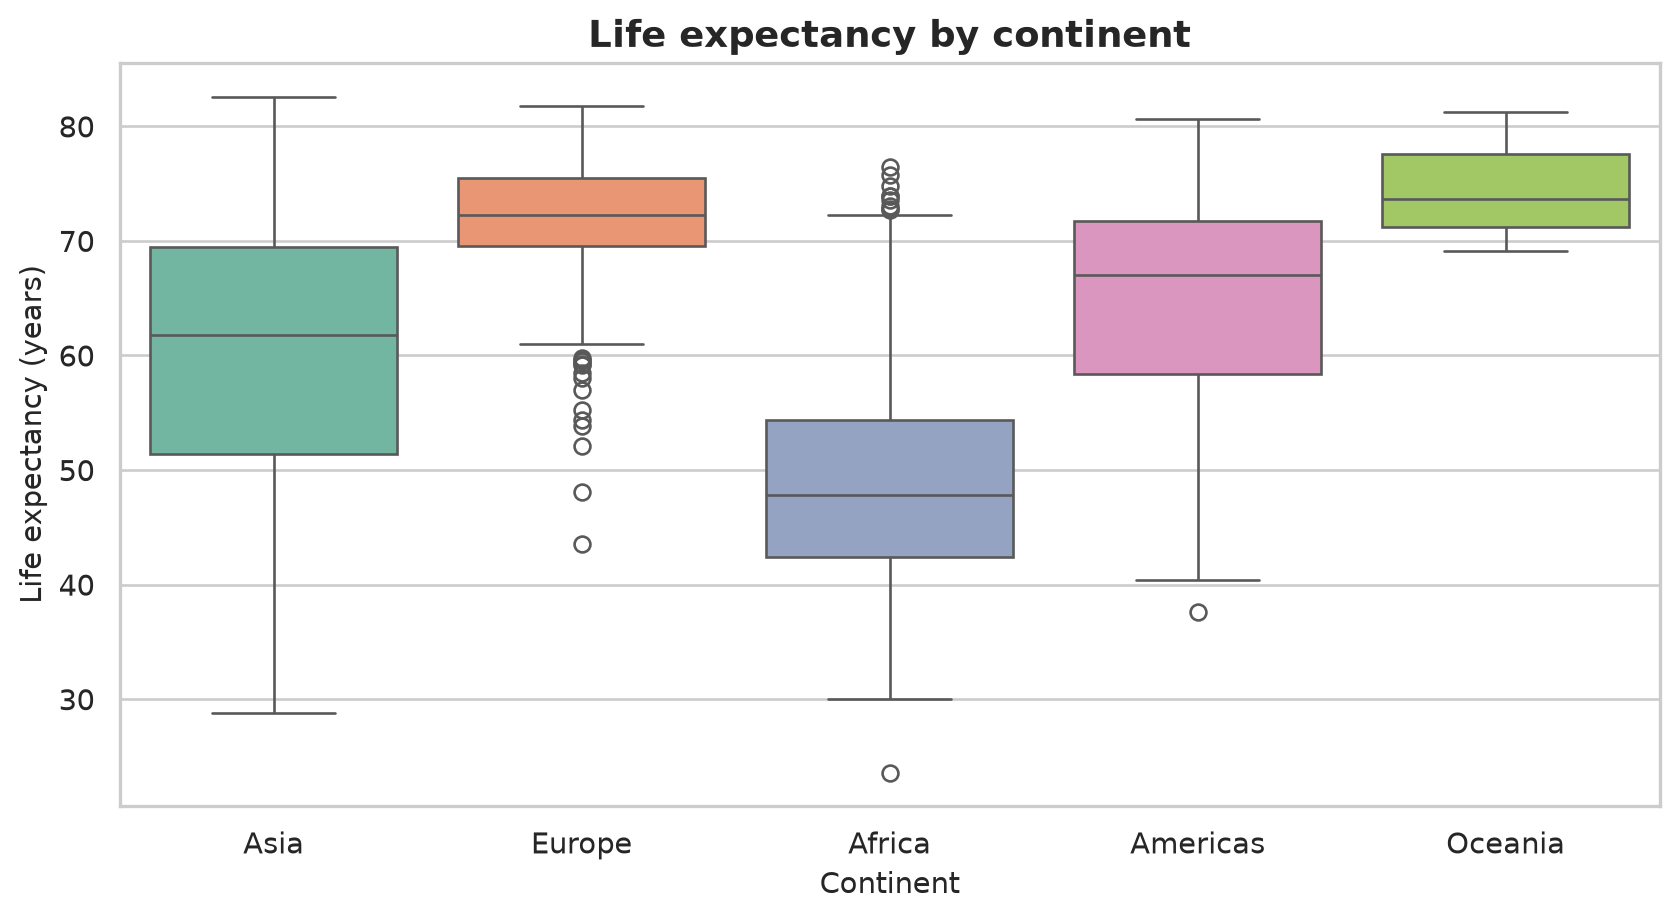

In [14]:
display(Image(filename=str(ROOT/'charts/08_continent_lifeexp_grouped_box.png'), width=800))

**So what?** Khác biệt châu lục hỗ trợ OneHotEncoder(continent).

## 09 continent lifeexp stacked bar

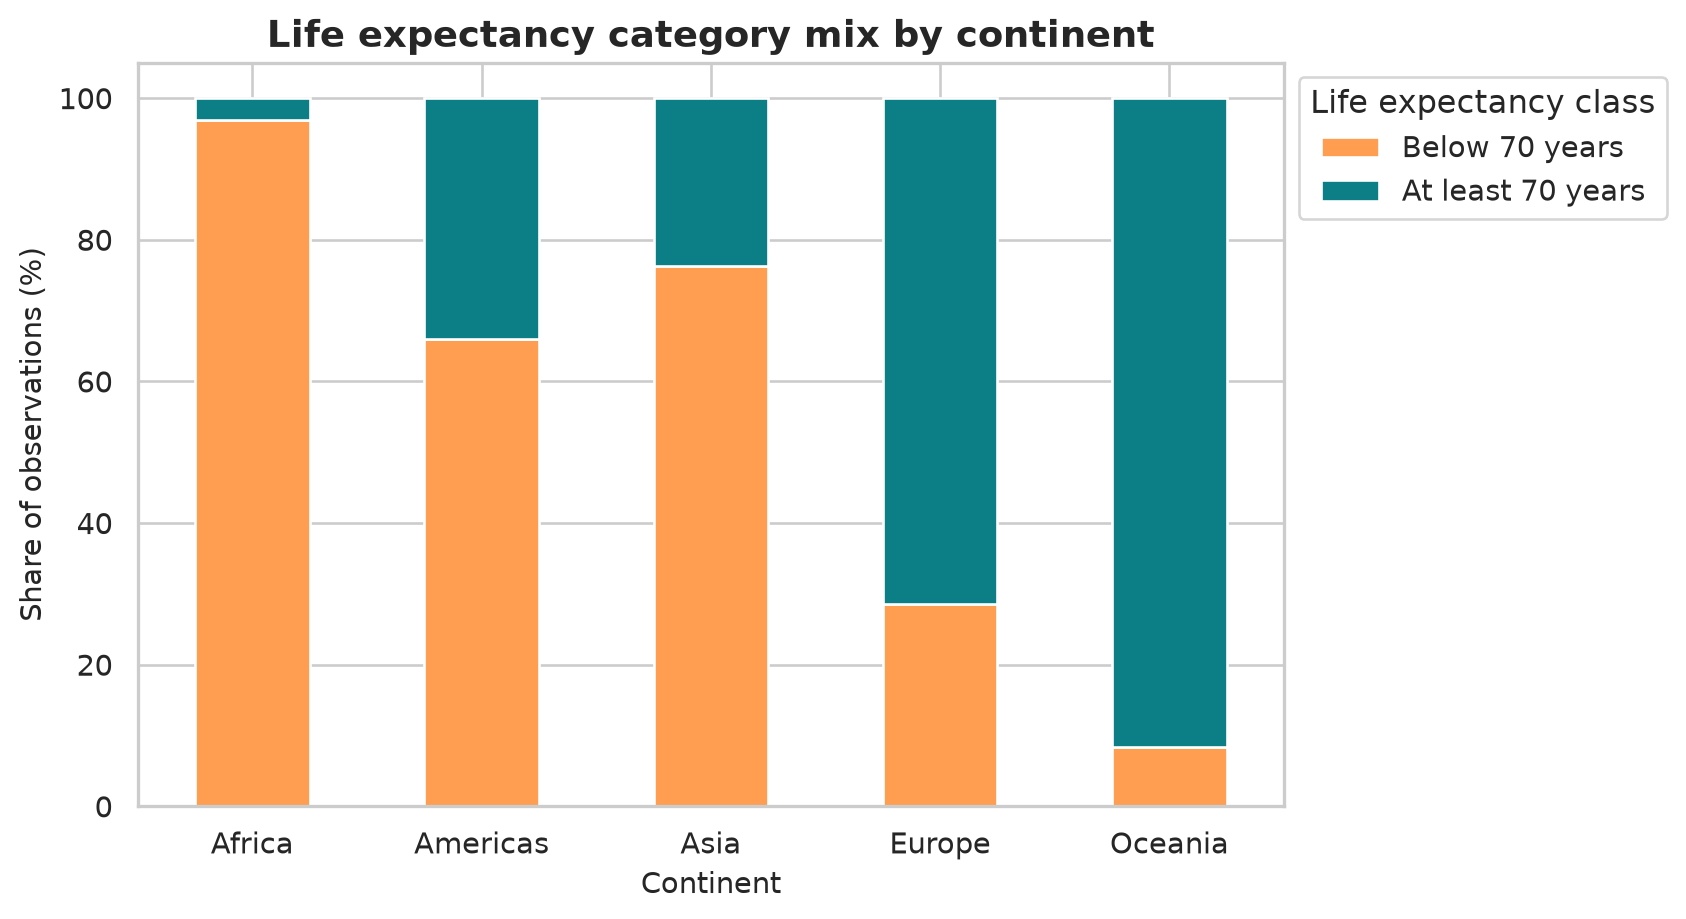

In [15]:
display(Image(filename=str(ROOT/'charts/09_continent_lifeexp_stacked_bar.png'), width=800))

**So what?** Tỷ lệ lớp không đều: class_weight balanced và F1 macro.

## 10 historical trend

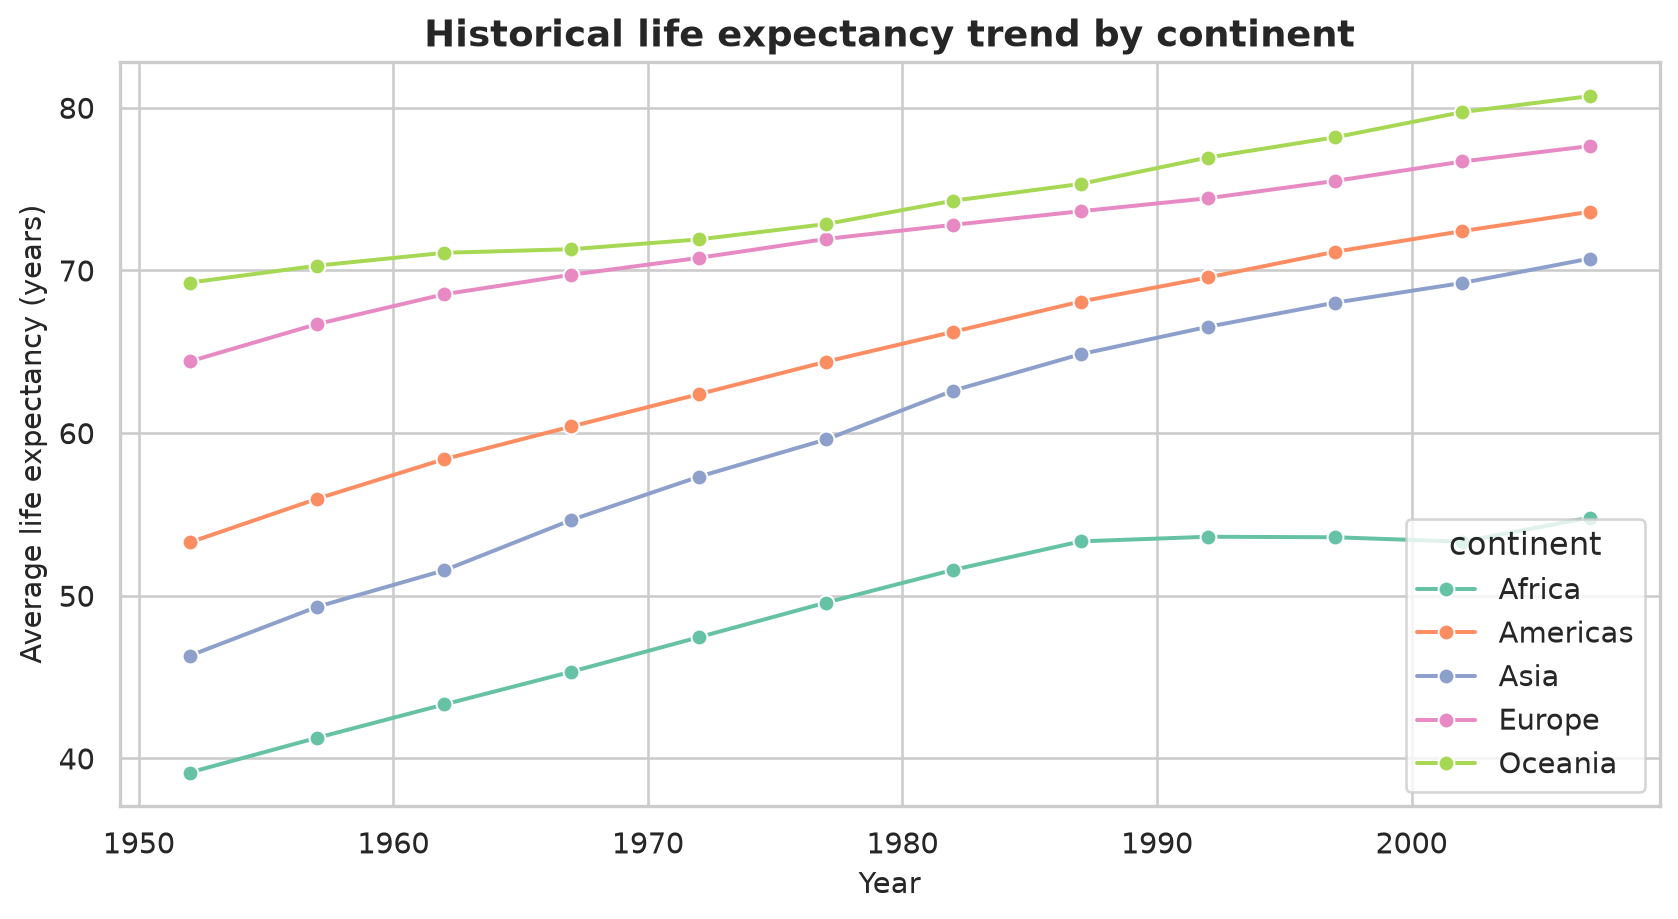

In [16]:
display(Image(filename=str(ROOT/'charts/10_historical_trend.png'), width=800))

**So what?** Một nước có nhiều năm: tách nước giữa fit/validation/test, không diễn giải thành dự báo tương lai.

## 11 pca cumulative variance

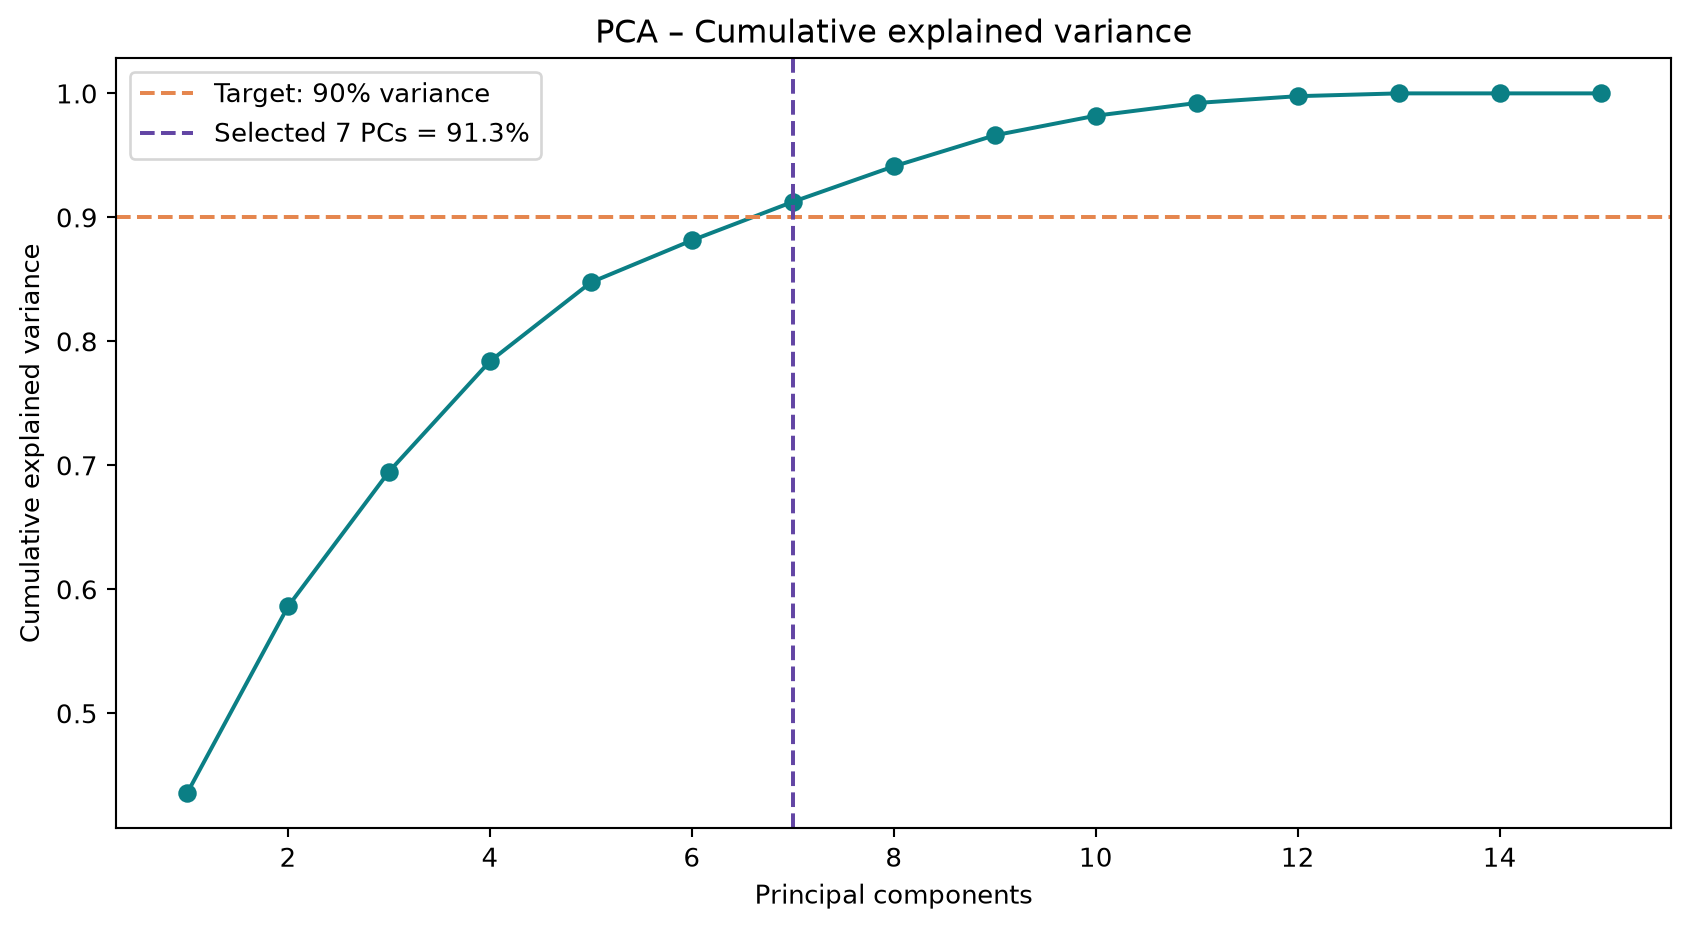

In [17]:
display(Image(filename=str(ROOT/'charts/11_pca_cumulative_variance.png'), width=800))

**So what?** PCA giữ 91.25% với 7 PC; không phải Accuracy.

## 12 kmeans elbow silhouette

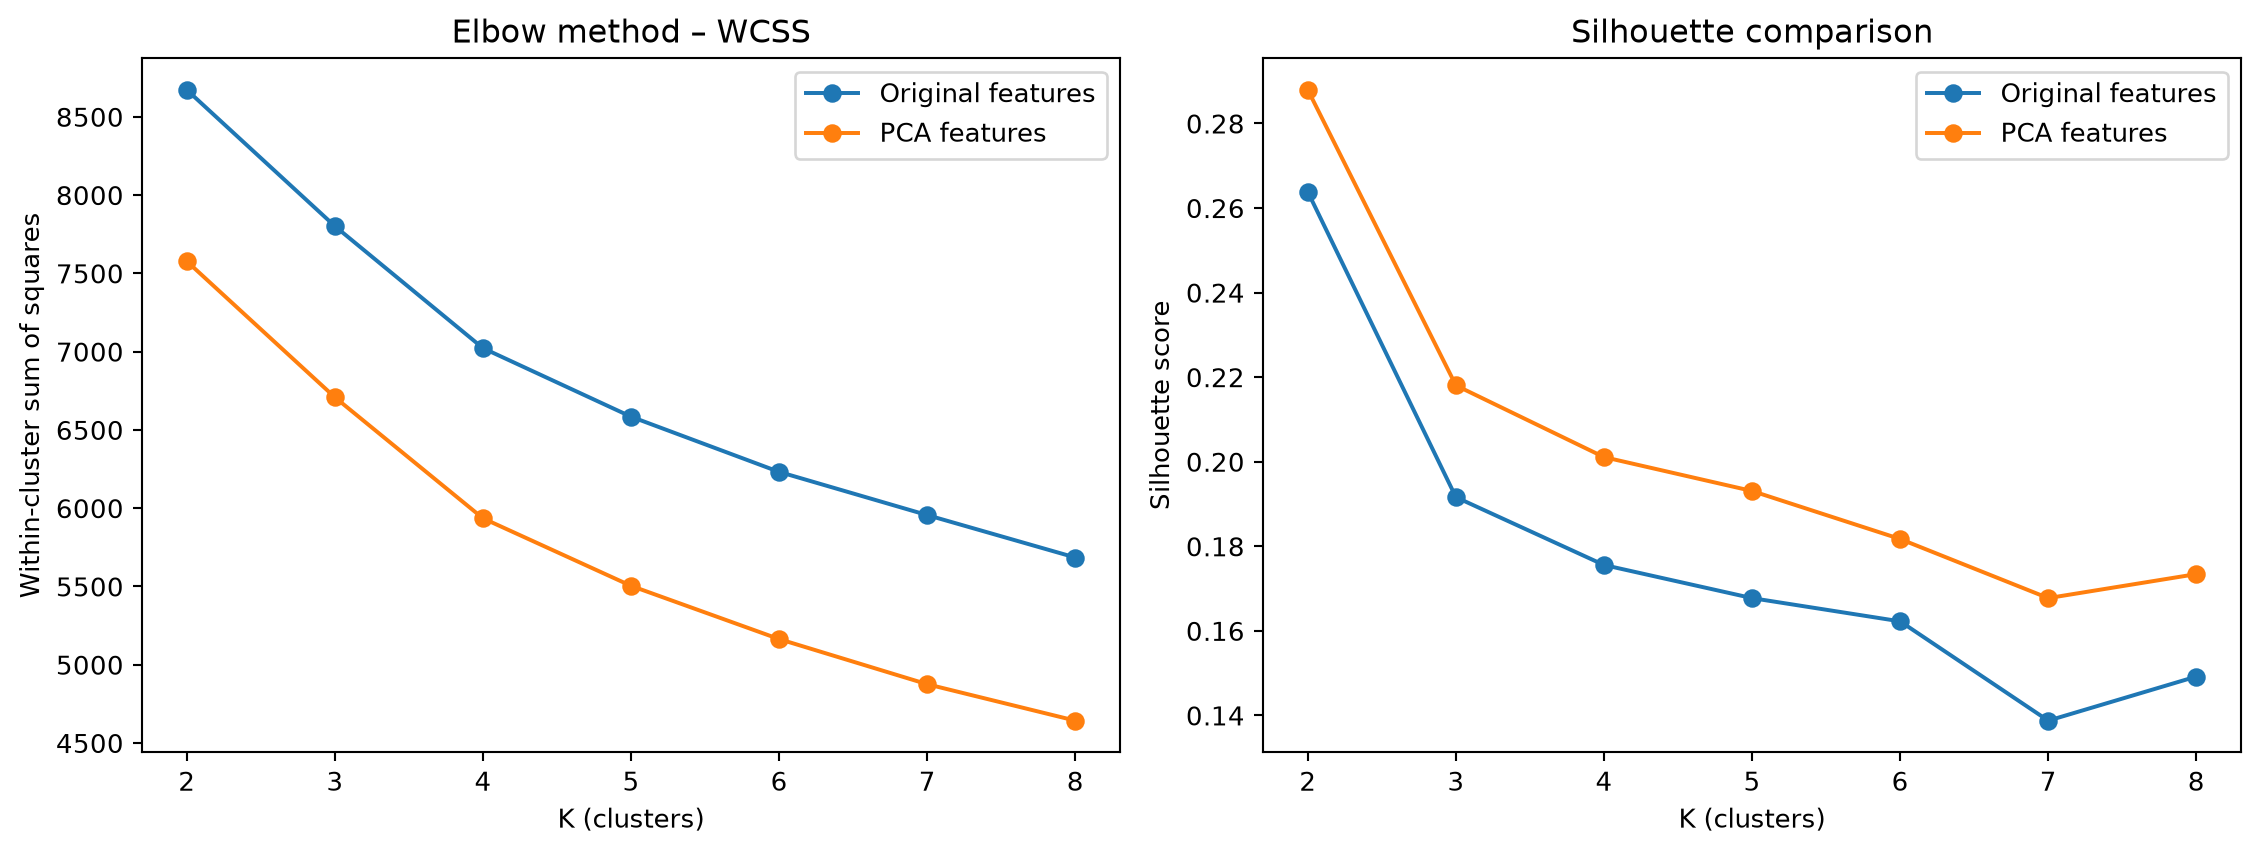

In [18]:
display(Image(filename=str(ROOT/'charts/12_kmeans_elbow_silhouette.png'), width=800))

**So what?** K=2 chọn theo Silhouette 0.2879; WCSS dùng tham khảo Elbow.

## 13 kmeans 2d clusters

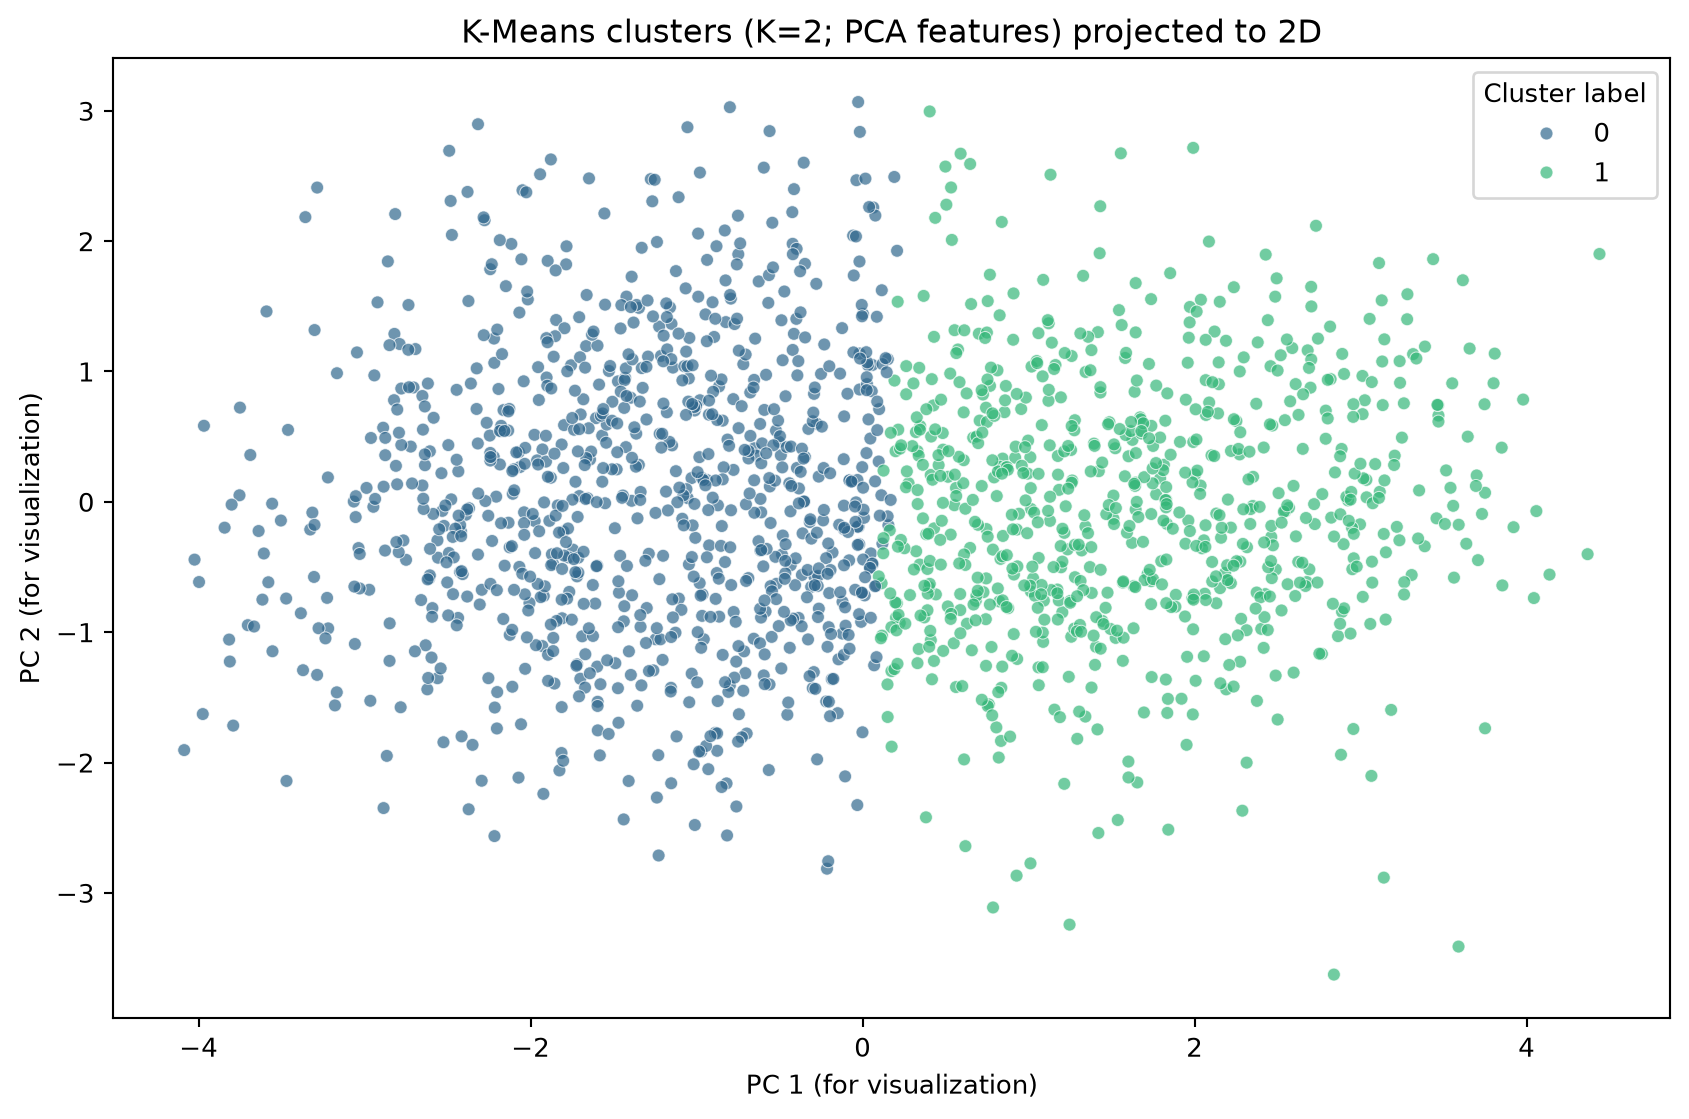

In [19]:
display(Image(filename=str(ROOT/'charts/13_kmeans_2d_clusters.png'), width=800))

**So what?** Hình 2D chỉ là phép chiếu; K-Means dùng các PC được chọn, không dùng target.

## 14 regression actual vs predicted

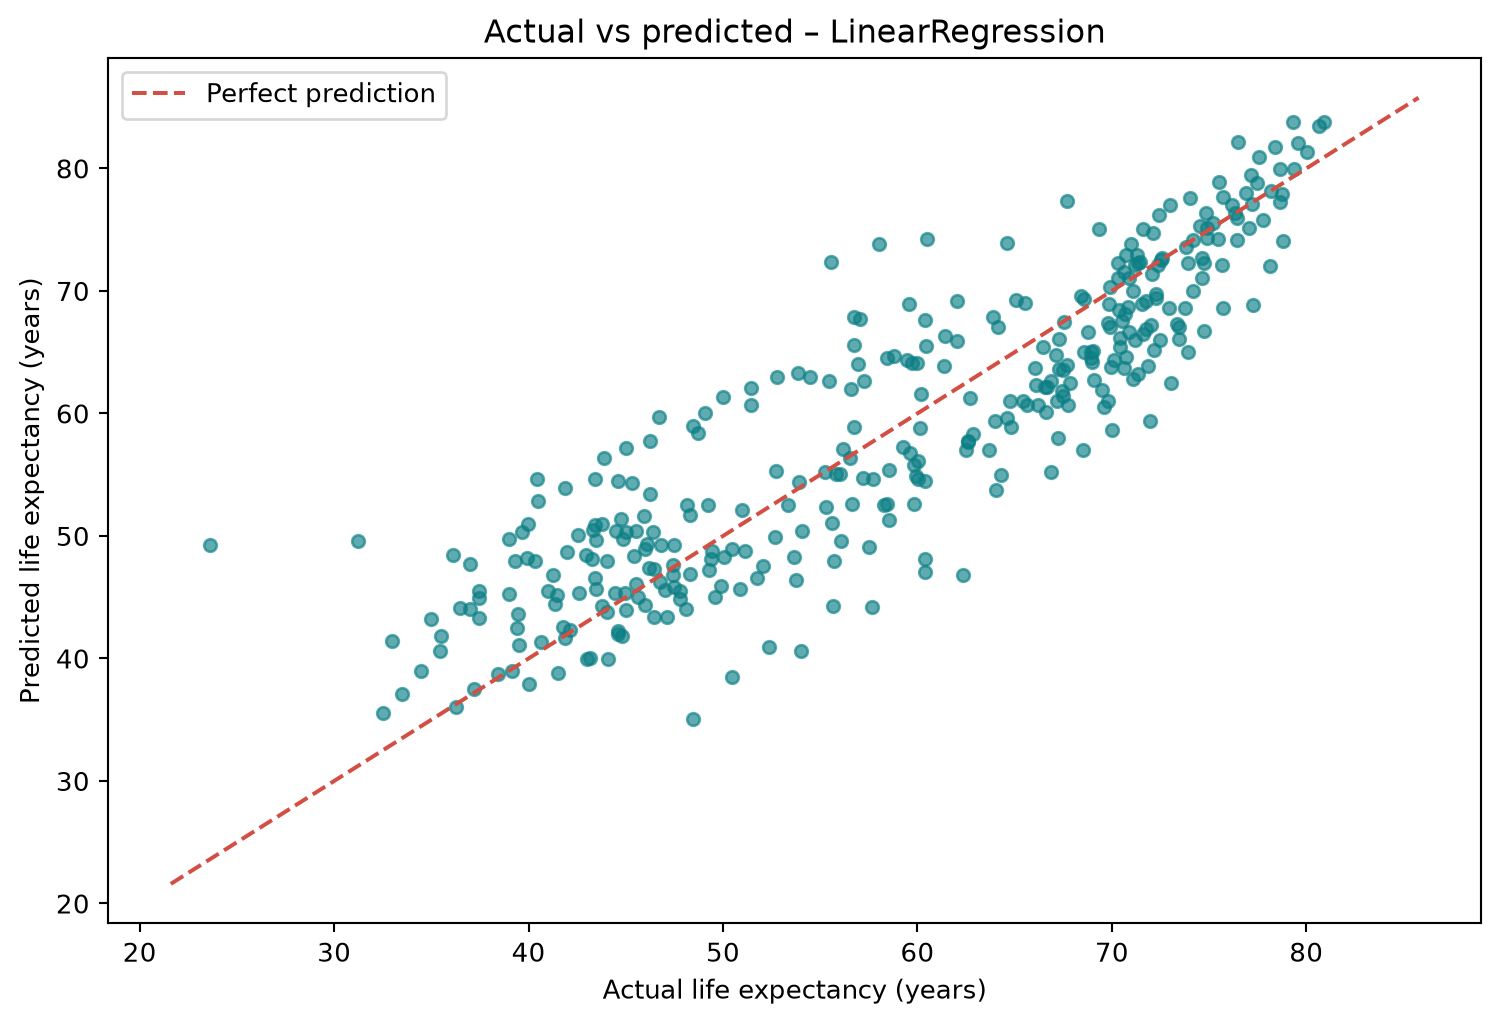

In [20]:
display(Image(filename=str(ROOT/'charts/14_regression_actual_vs_predicted.png'), width=800))

**So what?** Winner được chọn bằng validation; test RMSE 6.171 năm.

## 15 regression residual plot

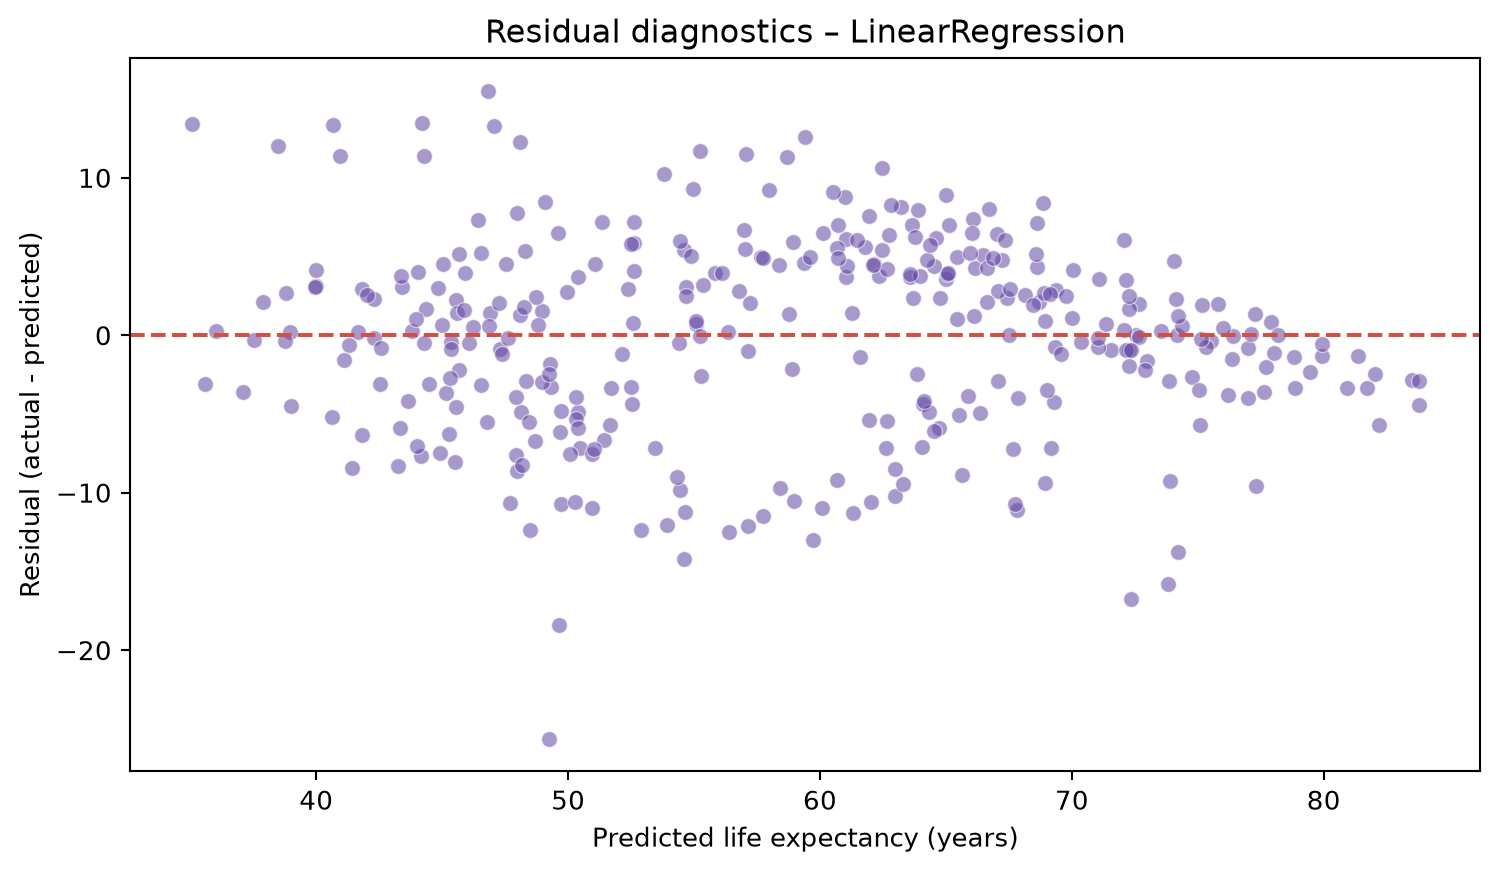

In [21]:
display(Image(filename=str(ROOT/'charts/15_regression_residual_plot.png'), width=800))

**So what?** Residual = thật − dự đoán. Cần xem cấu trúc lỗi, không chỉ một metric.

## 16 confusion matrix

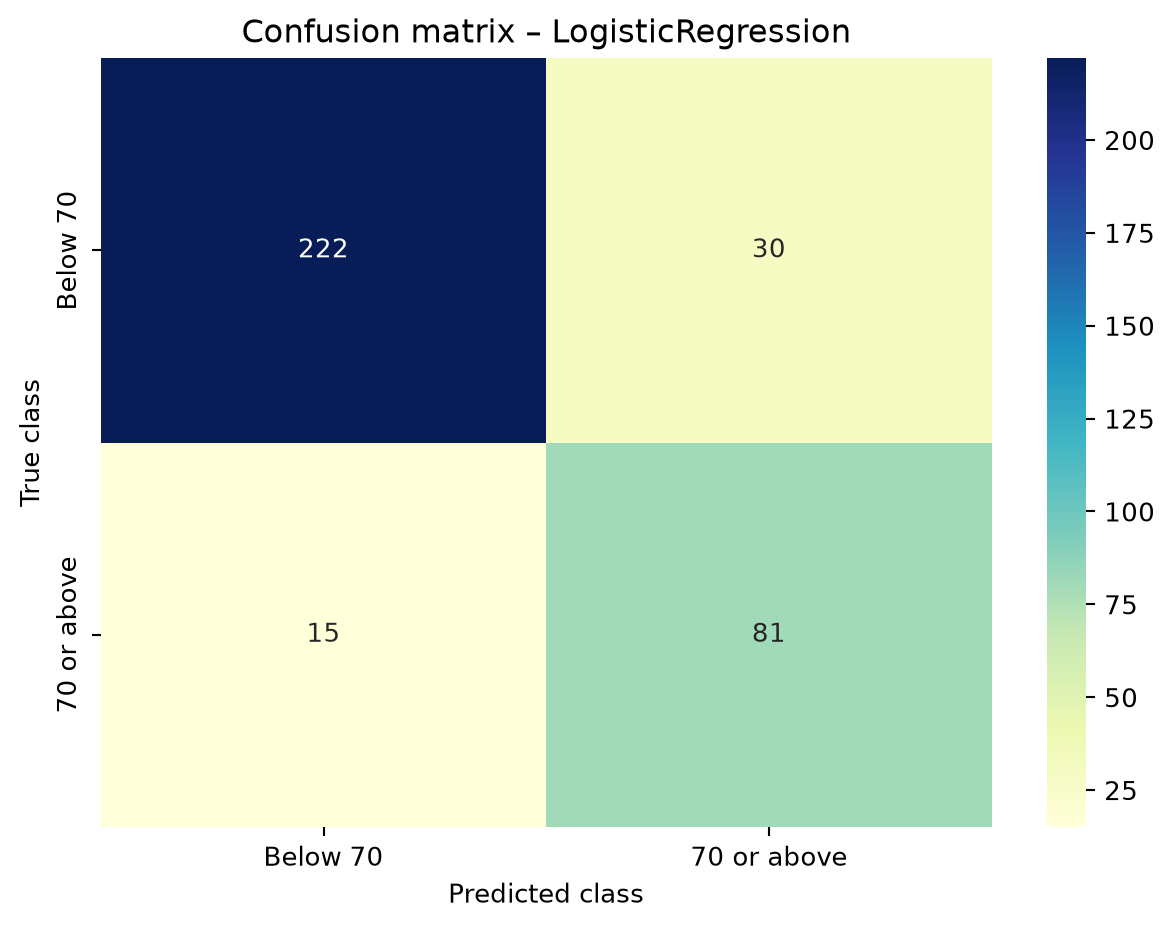

In [22]:
display(Image(filename=str(ROOT/'charts/16_confusion_matrix.png'), width=800))

**So what?** F1 macro 0.845; phân biệt lỗi từng lớp qua confusion matrix.

## 17 missingno matrix

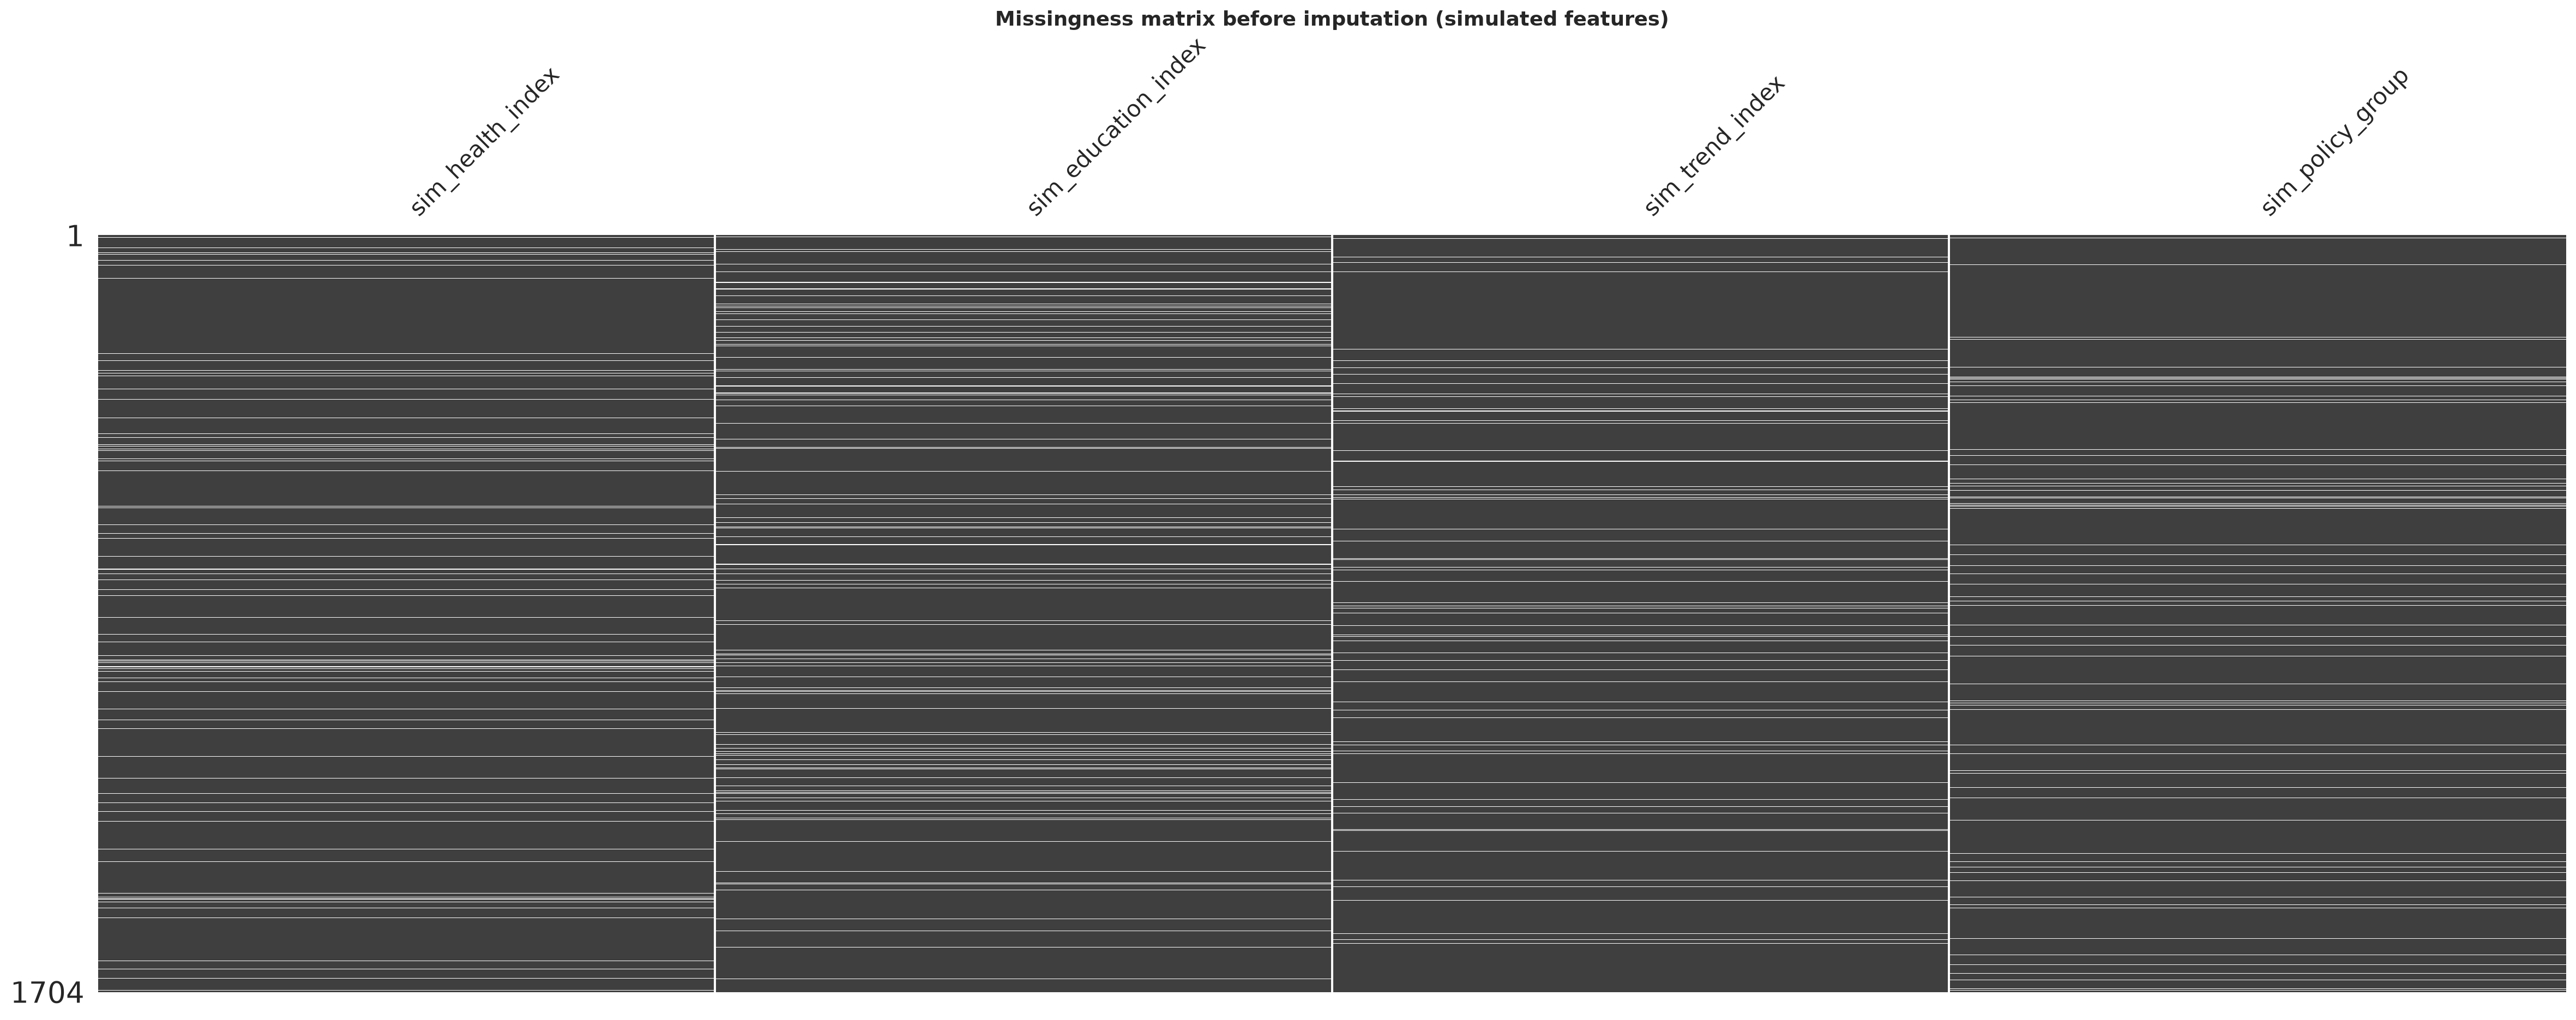

In [23]:
display(Image(filename=str(ROOT/'charts/17_missingno_matrix.png'), width=800))

**So what?** Missingno cho thấy cấu trúc thiếu trong các chỉ số mô phỏng, hỗ trợ kiểm tra trước điền.

## Validation và chọn winner

In [24]:
display(pd.read_csv(ROOT/'reports/validation_benchmark.csv').head(10))

,algorithm,task,score
0,LinearRegression,regression,6.261730
1,DecisionTreeRegressor,regression,7.406341
2,LogisticRegression,classification,0.883838
3,DecisionTreeClassifier,classification,0.834165


## Regression test

In [25]:
display(pd.read_csv(ROOT/'reports/regression_benchmark.csv').head(10))

,algorithm,MSE,RMSE,R2
0,LinearRegression,38.077309,6.170681,0.778112
1,DecisionTreeRegressor,45.162981,6.720341,0.736822


## Classification test

In [26]:
display(pd.read_csv(ROOT/'reports/classification_benchmark.csv').head(10))

,algorithm,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_positive
0,LogisticRegression,0.870690,0.833219,0.862351,0.845292,0.782609
1,DecisionTreeClassifier,0.850575,0.810185,0.832341,0.819703,0.745098


## ChromaDB đọc ngược DataFrame

In [27]:
display(pd.read_csv(ROOT/'reports/chroma_roundtrip.csv').head(10))

,record_id,cluster,continent,year,country,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6,pc_7
0,Afghanistan_1952,0,Asia,1952,Afghanistan,-3.754329,0.050206,-1.350897,1.674649,-1.034027,0.853395,0.842101
1,Afghanistan_1957,0,Asia,1957,Afghanistan,-2.108171,0.061805,-0.948214,0.356903,0.026833,0.709640,0.367252
2,Afghanistan_1962,0,Asia,1962,Afghanistan,-2.064686,0.267029,-0.773658,0.092524,-0.035684,0.631816,0.458693
3,Afghanistan_1967,0,Asia,1967,Afghanistan,-2.246519,0.508426,-0.697602,-0.307278,-0.642695,0.478069,0.615728
4,Afghanistan_1972,0,Asia,1972,Afghanistan,-2.325925,0.712398,-0.557373,-0.549526,-1.066669,-0.723836,1.102375
5,Afghanistan_1977,0,Asia,1977,Afghanistan,-1.011620,0.700665,-0.361185,0.265504,-0.890012,-0.266621,0.608806
6,Afghanistan_1982,0,Asia,1982,Afghanistan,-0.276627,0.598724,-0.118851,2.008736,-0.708267,0.698756,0.264747
7,Afghanistan_1987,0,Asia,1987,Afghanistan,-1.143083,1.029976,0.061450,-0.302796,-1.046903,0.665750,0.496297
8,Afghanistan_1992,0,Asia,1992,Afghanistan,-2.068049,1.451954,0.372086,-0.176649,-0.667878,0.546782,0.862500
9,Afghanistan_1997,0,Asia,1997,Afghanistan,-2.243706,1.784616,0.516032,-0.815968,-0.692898,-0.810616,1.444459


## Kiểm tra triển khai
HTTP UI/Chroma và restart đã test. Docker cần workflow xanh hoặc chạy Compose trên máy nhóm. Xem README để demo.

In [28]:
display(json.loads((ROOT/'reports/integration_status.json').read_text()))

{'http_db': True,
 'gradio_http': True,
 'restart_persistence': True,
 'docker_engine_tested': False}